# Noosaville hexagon test

This is testing that the 30-m resolution data from the Noosaville area can be used in the creation of a printable tile.

In [1]:
# standard imports
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D

mpl.rc('image', cmap='terrain')

import topohex as tph

#import loadData as LD
#import CoordinateTransform as CT
#import Hexagon as Hexagon
#import HexGrid as HexGrid

In [9]:
%%time
sea_value = -200

#n_rows, n_cols = 6000,6000 # default hard coded values obtained from .asc files

relative_path = ['.', 'data', 'srtm', 'rasters_SRTMGL1']
load_dir = os.path.join(*relative_path)
# values returned from tph.loadData.load_asc_format are the data, and the metadata for the grid

names = (
    'output_SRTMGL1',
)

loaded_data = {}
for name in names:
    fname = f'{name}.asc'
    try:
        D, m = tph.load.load_asc_format(load_dir, fname, seaVal=sea_value)
        loaded_data[name] = D
    except Exception as err: # assume exceptions arise from non-existant files, replace with sea val grid
        print(f'{name} => {err}')
        raise err
        
        #D = np.full( (n_rows, n_cols), sea_value )



for n, v in loaded_data.items():
    print(f'{n:>10} | {v.shape} | {np.min(v)} | {np.max(v)}')

IMG = loaded_data[names[0]]

output_SRTMGL1 | (3520, 4185) | -20.0 | 884.0
CPU times: user 1.48 s, sys: 26.6 ms, total: 1.5 s
Wall time: 1.51 s


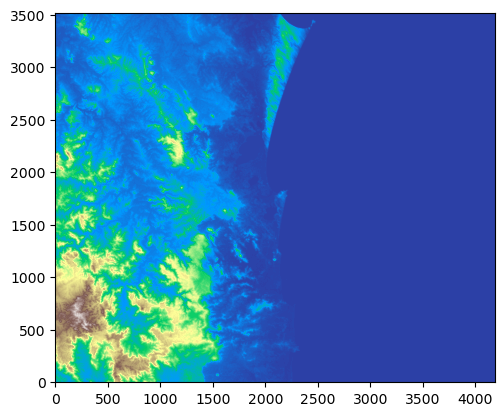

In [10]:
plt.imshow(IMG, aspect='equal', origin='lower')
plt.show()

# Coordinate transformations

The raw data is given in (lat, lon) coordinates which can be attributed to a `PlateCarree` coordinate transform.

I want to have the data in physical displacement (eating and northing) with respect to Noosaville.

This can be achieved in `cartopy` using the `cartopy.img_transform.regrid` or `cartopy.img_transform.warp_array` functions and the `Orthographic` projection.

In [4]:
import cartopy.crs as ccrs
from cartopy import img_transform as cimgt

In [5]:
proj_init = ccrs.PlateCarree()

In [6]:
target = {
    'lon':153.047693,
    'lat':-26.412448,
}

proj_target = ccrs.Orthographic(
    central_longitude = target['lon'],
    central_latitude = target['lat']
)

In [30]:
# getting the source coordinates as a meshgrid...
ny, nx = IMG.shape

x0 = m[0]
y0 = m[1]
dxy = m[2]

x = x0 + np.arange(nx)*dxy
y = y0 + np.arange(ny)*dxy
x,y = np.meshgrid(x,y)

In [182]:
# target coordinates
# I want +- 20km in both directions at 15m spacing...
lim = 25_000
dxy = 15

lim = lim - lim%dxy + dxy

target_xy = np.arange(-lim, lim+1, dxy)
target_x, target_y = np.meshgrid(target_xy, target_xy)

In [183]:
target_x

array([[-25005, -24990, -24975, ...,  24975,  24990,  25005],
       [-25005, -24990, -24975, ...,  24975,  24990,  25005],
       [-25005, -24990, -24975, ...,  24975,  24990,  25005],
       ...,
       [-25005, -24990, -24975, ...,  24975,  24990,  25005],
       [-25005, -24990, -24975, ...,  24975,  24990,  25005],
       [-25005, -24990, -24975, ...,  24975,  24990,  25005]])

In [184]:
target_y

array([[-25005, -25005, -25005, ..., -25005, -25005, -25005],
       [-24990, -24990, -24990, ..., -24990, -24990, -24990],
       [-24975, -24975, -24975, ..., -24975, -24975, -24975],
       ...,
       [ 24975,  24975,  24975, ...,  24975,  24975,  24975],
       [ 24990,  24990,  24990, ...,  24990,  24990,  24990],
       [ 25005,  25005,  25005, ...,  25005,  25005,  25005]])

In [185]:
%%time
IMG_transformed = cimgt.regrid(
    array=IMG,
    source_x_coords=x, 
    source_y_coords=y,
    source_proj=proj_init,
    target_proj=proj_target,
    target_x_points=target_x,
    target_y_points=target_y
)

CPU times: user 12.9 s, sys: 552 ms, total: 13.4 s
Wall time: 13.5 s


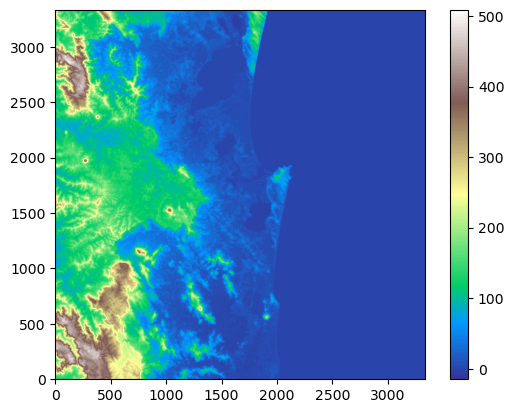

In [186]:
plt.imshow(IMG_transformed, aspect='equal', origin='lower')
plt.colorbar()
plt.show()

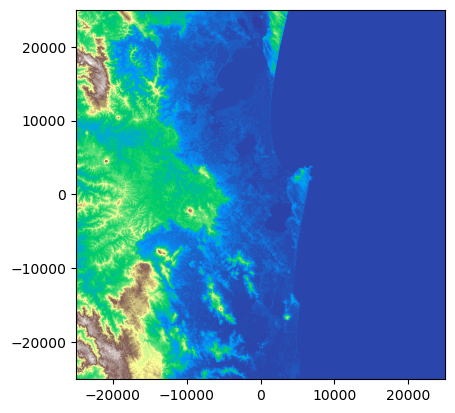

In [187]:
plt.pcolormesh(target_x, target_y, IMG_transformed)
plt.gca().set_aspect('equal')
plt.show()

# circular "hexagon" coordinates

In [200]:
coords_noosaville = np.array([
    target['lon'],
    target['lat']
])

H = tph.Hexagon(
    scale = 12_000, # edge length in m
    rotation = 0,
    centre = [0,0]
)

In [201]:
cull_value = -20

cull_map = IMG_transformed.copy()

cull_mask = H.outsideHexagon_grid(target_x, target_y)
cull_map[cull_mask] = cull_value

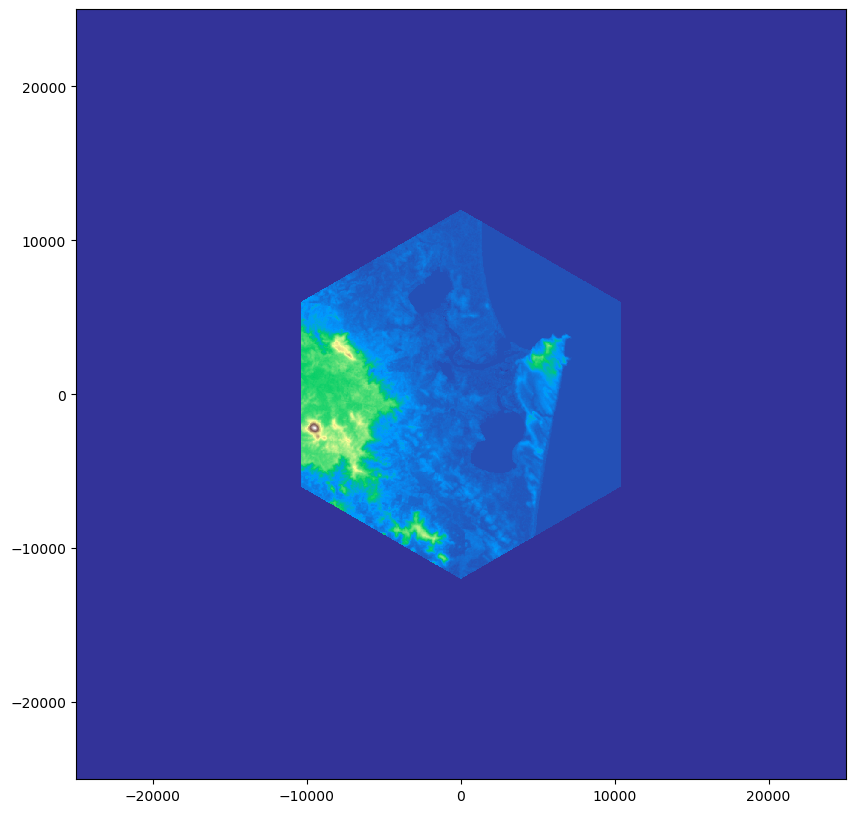

<Figure size 640x480 with 0 Axes>

In [202]:
fig, ax = plt.subplots(1,1, figsize=(10,10))

ax.pcolormesh(target_x,target_y, cull_map)
ax.set_aspect('equal')

plt.show()
plt.clf()

In [203]:
NUMHEX = 600

v0,f0 = tph.hexgrid.layerAlgorithm(H, NUMHEX)
nv = v0.shape[1] # number of vertices in the hexgrid

HexD = np.zeros((nv))
HexD_bottom = np.zeros((nv))

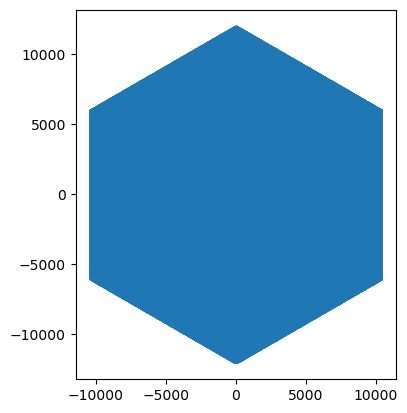

In [204]:
plt.scatter(v0[0,:], v0[1,:], s=1)
plt.gca().set_aspect('equal')
plt.show()

In [205]:
%%time
angles = np.arctan2(
    v0[0,:],
    v0[1,:]
)

scale_factor = 2 * np.cos( 
    np.deg2rad(
        np.mod(np.rad2deg(angles), 60) - 30
    )
) / np.sqrt(3)

v1 = v0 * scale_factor

CPU times: user 20.8 ms, sys: 3.85 ms, total: 24.6 ms
Wall time: 22.9 ms


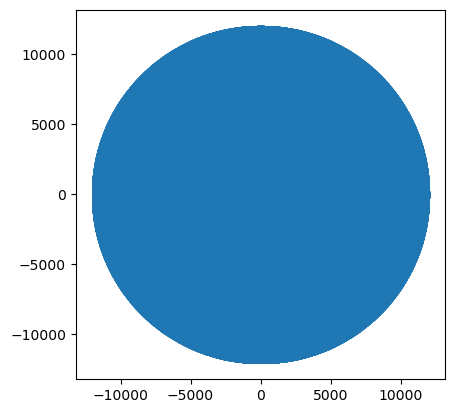

In [207]:
plt.scatter(v1[0,:], v1[1,:], s=1)
ax = plt.gca()
ax.set_aspect('equal')
#ax.set_ylim([-1000,1000])
#ax.set_xlim([14000,16000])
#ax.set_ylim([-200,200])
#ax.set_xlim([-200,200])
plt.show()